# 04 — Diagnostic (Path A, Stage 5a)

**Formal tests for branches A–C**, each with an effect size and a confidence interval, and one
Benjamini–Hochberg correction across every p-value in this notebook.

Two design choices follow from `01`–`03`:

1. **Rank-based tests.** Stats are skewed and have design extremes (Blissey, Shuckle), so the tests are
   Mann–Whitney and Kruskal–Wallis, with rank-biserial *r* and ε² as effect sizes.
2. **Evolution families are the independent unit for shape.** A family repeats one stat shape two or three times,
   so testing species would count one design several times and inflate significance. Type signatures are tested on
   **family means** (360 families), and confidence intervals resample families, not species.

| § | Question | Unit |
|---|---|---|
| 4.1 | Are the power tiers real? (legendary floor, Mega rule) | species / forms |
| 4.2 | How much of Total does type explain, compared with tier? | species, family bootstrap |
| 4.3 | Is there power creep across generations? | species and families |
| 4.4 | Which types have a stat signature that survives a family-level test? | families |
| 4.5 | Do dual-typed species carry a stat premium, and is it real? | species, within family |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
while not (ROOT / "archive" / "Pokemon.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARCHIVE = ROOT / "archive"
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS, MODELS = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "models"
for p in (RAW, PROC, REPORTS, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

KF_PATH = REPORTS / "_key_figures.json"
STATS = ["hp", "atk", "def", "spa", "spd", "spe"]
STAT_LABEL = {"hp": "HP", "atk": "Attack", "def": "Defense", "spa": "Sp. Atk", "spd": "Sp. Def", "spe": "Speed"}
SHARES = [f"sh_{s}" for s in STATS]


def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if hasattr(v, "item"):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    return v


def kf_update(**kw):
    """Append to reports/_key_figures.json — the only place the report reads numbers from."""
    kf = json.loads(KF_PATH.read_text(encoding="utf-8")) if KF_PATH.exists() else {}
    kf.update({k: _plain(v) for k, v in kw.items()})
    KF_PATH.write_text(json.dumps(kf, indent=1, sort_keys=True, ensure_ascii=False), encoding="utf-8")
    print(f"  _key_figures.json <- {', '.join(kw)}  ({len(kf)} figures total)")

import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#008A7E,#C1841C" --mode light --pairs all
#     PASS lightness | PASS chroma floor | PASS CVD separation (worst pair dE 12.5 protan)
#     PASS normal-vision separation (21.1) | PASS contrast >= 3:1 on white
# Charts here never need more than three identity colours: Blue = the focus series, Teal = the
# second series, Amber = reference lines / thresholds. Everything else is Grey context.
# DESIGN.md's Teal #00857C FAILS the chroma floor (C = 0.097 < 0.10, reads as grey), so it is
# nudged to #008A7E on the same hue. Navy is text ink only — never a series fill.
# Diverging (type signature heatmap): Amber (below average) <- light grey -> Blue (above average).
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER, CYAN = "#051C2C", "#2251FF", "#008A7E", "#C1841C", "#00A9F4"
SLATE, GREY, GRID, LIGHT = "#7F93A6", "#9FADB8", "#E9ECEF", "#D5DCE2"
C_FOCUS, C_SECOND, C_REF, C_CONTEXT = BLUE, TEAL, AMBER, GREY


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
SOURCE = "Pokemon.csv (Kaggle 'Pokemon with stats', main-series games, Generations 1–6)"


def finish(fig, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3. Placed under the lowest
    artist (axis labels, outside legends), so it never collides with them."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    y0 = min(ax.get_tightbbox(r).transformed(fig.transFigure.inverted()).y0 for ax in fig.axes)
    fig.text(0.005, y0 - 0.12 / fig.get_figheight(), f"Source: {SOURCE}" + (f" · {note}" if note else ""),
             fontsize=7, color=SLATE, ha="left", va="top")


def suptitle(fig, text, y=1.04):
    fig.suptitle(text, x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=y)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

df = pd.read_parquet(PROC / "pokemon_clean.parquet")
sp = df[df.is_species].copy()
sp["type1"] = sp.type1.cat.remove_unused_categories()
rng = np.random.default_rng(RANDOM_STATE)
TESTS = []          # every p-value in this notebook, corrected together at the end


def rank_biserial(a, b):
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    return 2 * u.statistic / (len(a) * len(b)) - 1, u.pvalue


def eps2_kruskal(groups):
    h, p = stats.kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    return (h - k + 1) / (n - k), p


def eta2(y, g):
    y = np.asarray(y, float); g = np.asarray(g)
    gm = y.mean()
    ssb = sum((y[g == k].mean() - gm) ** 2 * (g == k).sum() for k in np.unique(g))
    return ssb / ((y - gm) ** 2).sum()


def family_boot(fn, data, n=2000, basic=False):
    """95% CI that resamples evolution families (the independent unit), not species. basic=True gives the
    reverse-percentile interval, used for η², which is biased upward in resamples (duplicated families add
    between-group variance)."""
    fams = data.family.unique()
    by = {f: d for f, d in data.groupby("family")}
    out = []
    for _ in range(n):
        pick = rng.choice(fams, len(fams), replace=True)
        out.append(fn(pd.concat([by[f] for f in pick], ignore_index=True)))
    lo, hi = np.percentile(out, [2.5, 97.5])
    if basic:
        est = fn(data)
        return np.array([max(0.0, 2 * est - hi), 2 * est - lo])
    return np.array([lo, hi])


print(f"{len(sp)} species in {sp.family.nunique()} families")

721 species in 360 families


## 4.1 The power tiers

**Hypothesis:** legendary status sets a floor on Total; Mega Evolution is a fixed +100.

In [2]:
leg = sp.legendary_canon
r_leg, p_leg = rank_biserial(sp.total[leg], sp.total[~leg])
TESTS.append(("Total: legendary vs ordinary (Mann–Whitney)", p_leg, f"r = {r_leg:.2f}"))

rule = sp.total >= 580
tp, fp, fn = int((rule & leg).sum()), int((rule & ~leg).sum()), int((~rule & leg).sum())
tp_raw, fp_raw = int((rule & sp.legendary_raw).sum()), int((rule & ~sp.legendary_raw).sum())
print(f"legendary vs ordinary Total: rank-biserial r = {r_leg:.3f}, p = {p_leg:.1e}")
print(f"rule 'Total >= 580' vs legendary_canon: recall {tp}/{tp + fn}, precision {tp}/{tp + fp}")
print(f"                       vs raw flag    : recall {tp_raw}/{int(sp.legendary_raw.sum())}, precision {tp_raw}/{tp_raw + fp_raw}")
print("the rule's false positives:", ", ".join(sp.loc[rule & ~leg, "name"]))

megas = df[df.form_kind == "mega"].merge(sp[["dex", "total"]], on="dex", suffixes=("", "_sp"))
up = megas.total - megas.total_sp
print(f"\nMega uplift: exactly +100 in {(up == 100).sum()} of {len(up)}; range {up.min()}–{up.max()}")

legendary vs ordinary Total: rank-biserial r = 0.976, p = 7.1e-33
rule 'Total >= 580' vs legendary_canon: recall 53/54, precision 53/61
                       vs raw flag    : recall 46/46, precision 46/61
the rule's false positives: Dragonite, Tyranitar, Slaking, Salamence, Metagross, Garchomp, Hydreigon, Goodra

Mega uplift: exactly +100 in 47 of 48; range 90–100


The floor is close to exact. **Total ≥ 580 catches 53 of 54 legendary or mythical species** (all but Phione), and the
8 non-legendaries above it are the 7 pseudo-legendaries at 600 plus Slaking. Against the raw flag the rule catches all
46, but "misfires" on 15. Seven of those misfires are the flag's own errors (`01` §1.6), which is further evidence the
corrected flag is the right one.

## 4.2 What explains Total — type, tier or generation?

In [3]:
m = smf.ols("total ~ C(type1) + legendary_canon + C(generation) + is_dual_type", data=sp).fit()
a2 = sm.stats.anova_lm(m, typ=2)
a2["partial_eta2"] = a2.sum_sq / (a2.sum_sq + a2.loc["Residual", "sum_sq"])
print(a2.round(4))
for term in ["C(type1)", "legendary_canon", "C(generation)", "is_dual_type"]:
    TESTS.append((f"Total ~ {term} (type II ANOVA, adjusted)", float(a2.loc[term, "PR(>F)"]),
                  f"partial η² = {a2.loc[term, 'partial_eta2']:.3f}"))

marg = {"primary type": eta2(sp.total, sp.type1.astype(str)),
        "legendary / ordinary": eta2(sp.total, sp.legendary_canon),
        "generation": eta2(sp.total, sp.generation)}
ci_type = family_boot(lambda d: eta2(d.total, d.type1.astype(str)), sp, n=1000, basic=True)
ci_leg = family_boot(lambda d: eta2(d.total, d.legendary_canon), sp, n=1000, basic=True)
print("\nmarginal η² of Total:", {k: round(v, 3) for k, v in marg.items()})
print(f"  type CI {ci_type.round(3)}, legendary CI {ci_leg.round(3)}  (family bootstrap)")
print(f"model R² = {m.rsquared:.3f}: {1 - m.rsquared:.0%} of the variation in Total is left unexplained "
      "(most of it evolution stage, which the file does not record)")

                       sum_sq     df         F  PR(>F)  partial_eta2
C(type1)         2.409388e+05   17.0    1.6476  0.0479        0.0387
legendary_canon  1.794925e+06    1.0  208.6583  0.0000        0.2306
C(generation)    8.129524e+04    5.0    1.8901  0.0939        0.0134
is_dual_type     9.866276e+04    1.0   11.4694  0.0007        0.0162
Residual         5.987148e+06  696.0       NaN     NaN        0.5000



marginal η² of Total: {'primary type': np.float64(0.065), 'legendary / ordinary': np.float64(0.261), 'generation': np.float64(0.019)}
  type CI [0.005 0.084], legendary CI [0.197 0.322]  (family bootstrap)
model R² = 0.309: 69% of the variation in Total is left unexplained (most of it evolution stage, which the file does not record)


Legendary status alone explains about **26% of the variation in Total** and primary type about **7%**. Hold legendary
status, generation and dual typing fixed, and type's share falls to a partial η² of 0.04, which **does not survive the
BH correction** (q ≈ 0.11, table in §4.6). Much of type's raw link to Total is which types happen to contain legendaries.
Together the four terms leave roughly **69% unexplained**. The main driver of Total is evolution stage, which the file
does not record: a basic and a final form of the same line differ by 200 points or more.

## 4.3 Power creep across generations

In [4]:
ordn = sp[~sp.legendary_canon]
e_gen, p_gen = eps2_kruskal([g.total for _, g in ordn.groupby("generation")])
rho, p_rho = stats.spearmanr(ordn.generation, ordn.total)
rho_ci = family_boot(lambda d: stats.spearmanr(d.generation, d.total)[0], ordn)
TESTS.append(("Total by generation, ordinary species (Kruskal)", p_gen, f"ε² = {e_gen:.3f}"))
TESTS.append(("Total trend with generation, ordinary species (Spearman)", p_rho, f"ρ = {rho:.3f}"))

# family level: the strongest member of each family stands in for its final stage
fam = ordn.groupby("family").agg(generation=("generation", "first"), top=("total", "max"), n=("total", "size"))
e_fam, p_fam = eps2_kruskal([g.top for _, g in fam.groupby("generation")])
TESTS.append(("Family top Total by generation (Kruskal)", p_fam, f"ε² = {e_fam:.3f}"))
print(f"ordinary species: Kruskal ε² = {e_gen:.3f}, p = {p_gen:.3f};  Spearman ρ = {rho:.3f} {rho_ci.round(3)}, p = {p_rho:.2f}")
print(f"family top Total: Kruskal ε² = {e_fam:.3f}, p = {p_fam:.3f}")
print(fam.groupby("generation").top.median().rename("median family top Total").to_string())

g4 = ordn.generation == 4
r_g4, p_g4 = rank_biserial(ordn.total[g4], ordn.total[~g4])
TESTS.append(("Gen 4 vs other generations, ordinary species (Mann–Whitney)", p_g4, f"r = {r_g4:.2f}"))
print(f"\nGen 4 vs the rest: r = {r_g4:.3f}, p = {p_g4:.3f}")
print("Gen 4 species whose family began in an earlier generation (dex < 387 in the same family proxy):",
      "not detectable — cross-generation evolutions sit far apart in the dex")

ordinary species: Kruskal ε² = 0.010, p = 0.040;  Spearman ρ = 0.062 [0.006 0.12 ], p = 0.11
family top Total: Kruskal ε² = 0.076, p = 0.000
generation
1    490.0
2    455.0
3    466.0
4    500.0
5    490.0
6    500.0

Gen 4 vs the rest: r = 0.147, p = 0.023
Gen 4 species whose family began in an earlier generation (dex < 387 in the same family proxy): not detectable — cross-generation evolutions sit far apart in the dex


There is **no climb**, at most a faint drift. Among ordinary species, generation and Total correlate at ρ ≈ 0.06
(family-bootstrap interval 0.01 to 0.12), so generation accounts for well under 1% of the variation, and neither species-level
test survives the BH correction. At family level, where the strongest member of each line stands in for its final stage,
generations do differ (ε² ≈ 0.08), but as a **dip in Generations 2–3** (medians 455 and 466) rather than a rise: Generation 1
and Generation 5 both sit at 490, and Generations 4 and 6 at 500. The Gen 4 bump among species fits that generation adding late
evolutions to older lines (Magnezone, Rhyperior, Togekiss, …). The file cannot show this directly, because those evolutions sit
hundreds of dex numbers away from their families.

## 4.4 Type signatures — tested on families, not species

**Hypothesis (review):** Steel, Rock, Ghost and Dragon have clear signatures. For each type with ≥ 8 families and
each of the six stat shares: Mann–Whitney of that type's family means against all other families' means, with
rank-biserial *r*. A **signature** is any stat with *r* of at least 0.30 in absolute value (a medium effect) that
survives the BH correction.

In [5]:
famsh = sp.groupby("family").agg(type1=("type1", "first"), n=("dex", "size"), **{s: (s, "mean") for s in SHARES})
famsh["type1"] = famsh.type1.astype(str)
n_fam = famsh.type1.value_counts()
TESTABLE = [t for t in n_fam.index if n_fam[t] >= 8]
print(f"{len(famsh)} families; types with >= 8 families: {len(TESTABLE)} of 18 "
      f"(excluded: {', '.join(f'{t} ({n_fam[t]})' for t in n_fam.index if t not in TESTABLE)})")

rows = []
for t in TESTABLE:
    for s in SHARES:
        a, b = famsh.loc[famsh.type1 == t, s], famsh.loc[famsh.type1 != t, s]
        r, p = rank_biserial(a, b)
        rows.append({"type": t, "stat": STAT_LABEL[s[3:]], "families": len(a), "r": r, "p": p,
                     "diff_pp": (a.mean() - b.mean()) * 100})
sig = pd.DataFrame(rows)
TESTS.extend((f"signature {t} × {s} (family Mann–Whitney)", p, f"r = {r:.2f}")
             for t, s, r, p in sig[["type", "stat", "r", "p"]].itertuples(index=False))

# type explains how much of each share? Kruskal on family means, and species-level η² with a family bootstrap
expl = []
for s in SHARES:
    e, p = eps2_kruskal([g[s] for t, g in famsh.groupby("type1") if t in TESTABLE])
    TESTS.append((f"{STAT_LABEL[s[3:]]} share by type (family Kruskal)", p, f"ε² = {e:.3f}"))
    ci = family_boot(lambda d, s=s: eta2(d[s], d.type1.astype(str)), sp, n=1000, basic=True)
    expl.append({"measure": f"{STAT_LABEL[s[3:]]} share", "eta2_species": eta2(sp[s], sp.type1.astype(str)),
                 "ci_lo": ci[0], "ci_hi": ci[1], "eps2_family": e, "p_family": p})
ci = ci_type
expl.append({"measure": "Total", "eta2_species": marg["primary type"], "ci_lo": ci[0], "ci_hi": ci[1],
             "eps2_family": np.nan, "p_family": np.nan})
expl = pd.DataFrame(expl)
expl.round(3)

360 families; types with >= 8 families: 17 of 18 (excluded: Flying (2))


,measure,eta2_species,ci_lo,ci_hi,eps2_family,p_family
0,HP share,0.100,0.017,0.123,0.133,0.000
1,Attack share,0.187,0.085,0.225,0.181,0.000
2,Defense share,0.228,0.125,0.280,0.198,0.000
3,Sp. Atk share,0.276,0.177,0.325,0.285,0.000
4,Sp. Def share,0.066,0.000,0.077,0.044,0.014
5,Speed share,0.128,0.036,0.156,0.122,0.000
6,Total,0.065,0.005,0.084,NaN,NaN


### Exhibit 7 — Type explains at most about a quarter of the variation in any stat share, and little of Total

  saved reports/figures/ex07_variance.png


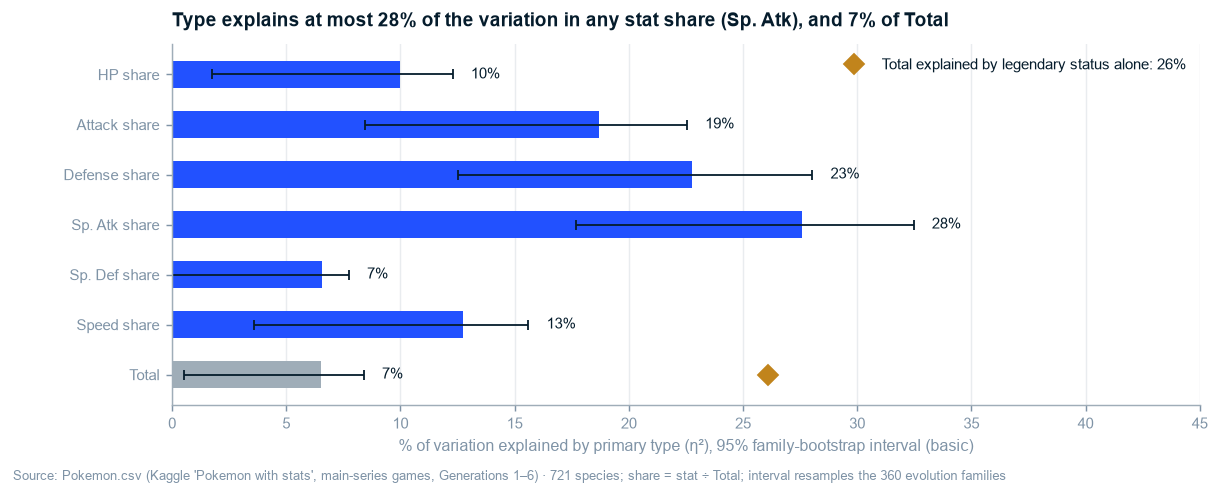

In [6]:
e = expl.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10.2, 3.6))
cols = [GREY if m == "Total" else BLUE for m in e.measure]
ax.barh(e.measure, e.eta2_species * 100, color=cols, height=0.55)
ax.errorbar(e.eta2_species * 100, range(len(e)), xerr=[(e.eta2_species - e.ci_lo) * 100, (e.ci_hi - e.eta2_species) * 100],
            fmt="none", ecolor=NAVY, elinewidth=1, capsize=3)
for y, (v, hi) in enumerate(zip(e.eta2_species, e.ci_hi)):
    ax.text(hi * 100 + 0.8, y, f"{v:.0%}", va="center", fontsize=8.5, color=NAVY)
leg_eta = marg["legendary / ordinary"] * 100
ax.plot([leg_eta], [list(e.measure).index("Total")], marker="D", color=AMBER, ms=8, ls="none",
        label=f"Total explained by legendary status alone: {leg_eta:.0f}%")
ax.set_xlim(0, 45); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("% of variation explained by primary type (η²), 95% family-bootstrap interval (basic)")
ax.legend(loc="upper right")
top = expl.loc[expl.measure != "Total"].sort_values("eta2_species").iloc[-1]
ax.set_title(f"Type explains at most {top.eta2_species:.0%} of the variation in any stat share "
             f"({top.measure.replace(' share', '')}), and {marg['primary type']:.0%} of Total")
finish(fig, "721 species; share = stat ÷ Total; interval resamples the 360 evolution families")
save(fig, "ex07_variance.png")
plt.show()

**So What:** even for the stat it shapes most, primary type leaves three-quarters of the variation to other
things: the line's role, its stage, its second type. For Total it explains about 7%, a quarter of what legendary status
alone explains.

**Implication:** type is a *tilt*, not a template. Where a signature exists it is worth respecting, but no type
pins down a stat line, and a designer should expect most creatures of a type to look like the average creature plus
a few points in its signature stat.

## 4.5 Dual-type premium

In [7]:
r_dual, p_dual = rank_biserial(sp.total[sp.is_dual_type], sp.total[~sp.is_dual_type])
TESTS.append(("Total: dual- vs single-typed species (Mann–Whitney)", p_dual, f"r = {r_dual:.2f}"))
med = sp.groupby("is_dual_type").total.median()
print(f"species: dual median {med[True]:.0f} vs single {med[False]:.0f}; r = {r_dual:.3f}, p = {p_dual:.1e}")

# within families that mix single- and dual-typed members: is the dual-typed member the later (stronger) one?
mixed = sp.groupby("family").filter(lambda g: g.is_dual_type.nunique() == 2)
within = mixed.groupby("family").apply(lambda g: g.loc[g.is_dual_type, "total"].mean() - g.loc[~g.is_dual_type, "total"].mean())
w = stats.wilcoxon(within)
TESTS.append(("within-family dual minus single Total (Wilcoxon)", w.pvalue, f"median {within.median():+.0f}"))
print(f"families with both: {len(within)}; within-family dual − single Total: median {within.median():+.0f}, "
      f"positive in {(within > 0).mean():.0%}, Wilcoxon p = {w.pvalue:.1e}")

species: dual median 452 vs single 405; r = 0.150, p = 4.8e-04
families with both: 52; within-family dual − single Total: median +160, positive in 83%, Wilcoxon p = 1.5e-08


Dual-typed species have a higher median Total (452 against 405). The within-family comparison shows why: in
families that mix the two, the dual-typed member is usually the *later* stage. Lines gain a second type as they evolve
(Charmander → Charizard gains Flying). The "dual-type premium" is an evolution-stage effect, not a design rule, so it
does not enter the recommendations.

## 4.6 Benjamini–Hochberg across every test in this notebook, and the signature list

In [8]:
tests = pd.DataFrame(TESTS, columns=["test", "p", "effect"])
tests["q_bh"] = multipletests(tests.p, method="fdr_bh")[1]
tests["significant"] = tests.q_bh < 0.05
tests.to_csv(REPORTS / "_tests.csv", index=False)
print(f"{len(tests)} tests corrected together; {tests.significant.sum()} survive BH at q < 0.05\n")
print(tests[~tests.test.str.startswith("signature")]
      .assign(p=lambda d: d.p.map("{:.1e}".format), q_bh=lambda d: d.q_bh.map("{:.1e}".format)).to_string(index=False))

sig["q_bh"] = tests.set_index("test").loc[[f"signature {t} × {s} (family Mann–Whitney)" for t, s in zip(sig.type, sig.stat)], "q_bh"].to_numpy()
sig["signature"] = (sig.q_bh < 0.05) & (sig.r.abs() >= 0.30)
sig.to_csv(REPORTS / "_signatures.csv", index=False)
hits = sig[sig.signature].sort_values("r", key=abs, ascending=False)
SIG_TYPES = list(dict.fromkeys(hits.type))
print(f"\nsignature types ({len(SIG_TYPES)} of {len(TESTABLE)} testable): {', '.join(SIG_TYPES)}")
print(f"no signature: {', '.join(t for t in TESTABLE if t not in SIG_TYPES)}")
hits[["type", "stat", "families", "diff_pp", "r", "q_bh"]].round(3)

119 tests corrected together; 39 survive BH at q < 0.05

                                                       test       p             effect    q_bh  significant
                Total: legendary vs ordinary (Mann–Whitney) 7.1e-33           r = 0.98 4.3e-31         True
                 Total ~ C(type1) (type II ANOVA, adjusted) 4.8e-02 partial η² = 0.039 1.1e-01        False
          Total ~ legendary_canon (type II ANOVA, adjusted) 1.5e-41 partial η² = 0.231 1.8e-39         True
            Total ~ C(generation) (type II ANOVA, adjusted) 9.4e-02 partial η² = 0.013 1.9e-01        False
             Total ~ is_dual_type (type II ANOVA, adjusted) 7.5e-04 partial η² = 0.016 3.3e-03         True
            Total by generation, ordinary species (Kruskal) 4.0e-02         ε² = 0.010 1.0e-01        False
   Total trend with generation, ordinary species (Spearman) 1.1e-01          ρ = 0.062 2.1e-01        False
                   Family top Total by generation (Kruskal) 3.3e-05         ε² 

,type,stat,families,diff_pp,r,q_bh
86,Steel,Defense,12,8.236,0.751,0.000
44,Rock,Defense,19,8.791,0.672,0.000
73,Fighting,Attack,12,5.400,0.643,0.001
51,Ground,Sp. Atk,17,-4.426,-0.585,0.000
101,Fairy,Speed,9,-4.577,-0.556,0.017
19,Psychic,Attack,27,-4.209,-0.547,0.000
75,Fighting,Sp. Atk,12,-4.386,-0.547,0.005
41,Electric,Speed,22,5.383,0.535,0.000
45,Rock,Sp. Atk,19,-4.151,-0.504,0.001
47,Rock,Speed,19,-4.789,-0.503,0.001


**Signatures that survive.** The list above is the evidence for Part III: each named type moves at least one stat
share by a medium-or-larger effect, tested on independent families and corrected for every comparison here.
Types not on the list either have no consistent tilt or have too few families to tell.

In [9]:
best = hits.groupby("type").apply(lambda g: g.loc[g.r.abs().idxmax()])
kf_update(
    r_legendary_total=float(r_leg), rule580_recall=f"{tp}/{tp + fn}", rule580_precision=f"{tp}/{tp + fp}",
    rule580_tp=tp, rule580_fp=fp, rule580_fn=fn, rule580_fp_raw=fp_raw,
    eta2_total_type=float(marg["primary type"]), eta2_total_legendary=float(marg["legendary / ordinary"]),
    eta2_total_generation=float(marg["generation"]), eta2_total_type_ci=list(ci_type), eta2_total_leg_ci=list(ci_leg),
    total_model_r2=float(m.rsquared), partial_eta2_type=float(a2.loc["C(type1)", "partial_eta2"]),
    gen_eps2=float(e_gen), gen_p=float(p_gen), gen_rho=float(rho), gen_rho_ci=list(rho_ci), gen_rho_p=float(p_rho),
    gen_family_eps2=float(e_fam), gen_family_p=float(p_fam), gen4_r=float(r_g4),
    gen_q={t: float(q) for t, q in zip(tests.test, tests.q_bh) if "generation" in t or "Gen 4" in t},
    n_testable_types=len(TESTABLE), sig_types=SIG_TYPES, n_sig_types=len(SIG_TYPES),
    nosig_types=[t for t in TESTABLE if t not in SIG_TYPES],
    untestable_types=[t for t in n_fam.index if t not in TESTABLE],
    sig_best={t: {"stat": best.loc[t, "stat"], "diff_pp": float(best.loc[t, "diff_pp"]), "r": float(best.loc[t, "r"])}
              for t in best.index},
    sig_all={t: [{"stat": s, "diff_pp": float(d), "r": float(r)} for s, d, r in g[["stat", "diff_pp", "r"]].values]
             for t, g in hits.groupby("type")},
    eta2_share={r.measure: float(r.eta2_species) for r in expl.itertuples()},
    eta2_share_max=float(top.eta2_species), eta2_share_max_stat=top.measure.replace(" share", ""),
    eta2_share_max_ci=[float(top.ci_lo), float(top.ci_hi)],
    dual_median=float(med[True]), single_median=float(med[False]), dual_r=float(r_dual),
    dual_within_median=float(within.median()), dual_within_pos=float((within > 0).mean()), dual_within_n=int(len(within)),
    n_tests=int(len(tests)), n_significant_bh=int(tests.significant.sum()),
)

  _key_figures.json <- r_legendary_total, rule580_recall, rule580_precision, rule580_tp, rule580_fp, rule580_fn, rule580_fp_raw, eta2_total_type, eta2_total_legendary, eta2_total_generation, eta2_total_type_ci, eta2_total_leg_ci, total_model_r2, partial_eta2_type, gen_eps2, gen_p, gen_rho, gen_rho_ci, gen_rho_p, gen_family_eps2, gen_family_p, gen4_r, gen_q, n_testable_types, sig_types, n_sig_types, nosig_types, untestable_types, sig_best, sig_all, eta2_share, eta2_share_max, eta2_share_max_stat, eta2_share_max_ci, dual_median, single_median, dual_r, dual_within_median, dual_within_pos, dual_within_n, n_tests, n_significant_bh  (95 figures total)


## Stage 5a — Gate Checklist

- [x] Tests chosen for the data: rank-based (skew, design extremes); families as the unit for shape (non-independence)
- [x] Assumptions checked and documented: independence handled by family aggregation and family bootstrap; no
      normality assumed except in the type II ANOVA, which is used only for variance shares
- [x] Effect sizes with every p-value (rank-biserial *r*, ε², η², partial η²), bootstrap intervals that resample families
- [x] Multiple comparisons corrected: one Benjamini–Hochberg pass over every test in the notebook
- [x] Results interpreted in design terms: a 580 floor, +100 Megas, no creep, type as a tilt, signatures for named types only